## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.
- `resec`: Resection area

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "spike11"

# data
fwd = dm.load(sub, "fwd")
ave = dm.load(sub, "ave", task="spike")
ncov = dm.load(sub, "cov", task="spike")
eig = dm.load(sub, "eig", atlas="probcon")
resec = dm.load(sub, "resec-ramp", space="pre")      # ground truth
ras2tkras = dm.load(sub, "ras2tkras")

## 🧬 - Data Processing
Estimate regularization parameter

In [9]:
snr, snr_db = mm.analysis.eeg.estimate_evoked_snr(evoked=ave, baseline=(0.0, 0.2), noise_cov=ncov)
lambda2 = 1.0 / (snr.max()**2)

print(f"Estimated SNR: {snr.max():.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

# cap the regularization parameter. Smaller values don't regularize anymore
lambda2 = max(0.01, lambda2)

    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 1.8e-17 (2.2e-16 eps * 204 dim * 0.0004  max singular value)
    Estimated rank (eeg): 203
    EEG: rank 203 computed from 204 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 203 (1 small eigenvalues omitted)
Estimated SNR: 158.273
Estimated lambda2: 0.000


Apply inverse solver

In [10]:
# --------------------------------
# Methods implemented in MindMap
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# --------------------------------

# mindmap's CSET
inv = mm.analysis.inverse.CSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
    eigenvectors = eig["vec"],
)

#cset = inv.solve(ave, lambda2=lambda2)


# mindmap's wCSET
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0,
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 0.8,
)

wcset = inv.solve(ave, lambda2=lambda2)

# mindmap's MCE
inv = mm.analysis.inverse.MCE(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
)

#mce = inv.solve(ave, lambda2=lambda2)


# -----------------------------------
# Methods implemented in MNE-Python
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# -----------------------------------


inv_mne = mne.minimum_norm.make_inverse_operator(
    info = ave.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

# MNE-python's sLORETA
sloreta = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

# MNE-python's dSPM
dspm = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "dSPM",
)

Computing inverse operator with 204 channels.
    204 out of 204 channels remain after picking
Selected 204 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 1.8e-17 (2.2e-16 eps * 204 dim * 0.0004  max singular value)
    Estimated rank (eeg): 203
    EEG: rank 203 computed from 204 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 8.04594
    scaling factor to adjust the trace = 1.40265e+23 (nchan = 204 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 1
   

Evaluate reconstructions

We evaluate against the resection with two complementary metrics, rather than a vertex-wise precision-recall / AP treatment: `find_peak_resection_distance` and `find_earliest_resection_cluster`. AP and precision-at-recall fold several failure modes into one scalar that's hard to read at a glance (a low AP can mean either diffuse low-amplitude spread or one sharp but mislocated cluster, for opposite reasons), so we use two separately-legible numbers instead.

`find_peak_resection_distance` is the classic ESI baseline: how far is the single loudest vertex from the resection (0 mm if it lands inside it), measured against the resection's own voxel geometry rather than a coarser vertex-sampled approximation of it. It's simple and literature-standard, but blind to multifocal maps -- a real hit can be outvoted by a taller unrelated peak elsewhere, which is exactly epilepsy's typical network-level presentation.

`find_earliest_resection_cluster` complements it directly: sweeping the amplitude threshold from strict to loose, how much of the cortex has to be marked active before *any* connected cluster of meaningful size (`min_cluster_area`) first touches the resection -- lower is better. This still gives credit to a genuine multifocal hit even when it isn't the single global maximum, and its `cluster_precision` output separately answers whether that cluster actually grew from inside the resection or merely grazed it from outside.

## 🎯 - Design decision: minimum cluster size

The next metric below sweeps the amplitude threshold and asks "how much of the cortex do we need to mark active before a connected cluster of dipoles first touches the resection?" That only means something if we require the cluster to be big enough to not just be a lucky arrangement of noise — so before implementing it, we grounded the minimum cluster size in two independent sources rather than picking a number.

**Literature**: combined EEG/MEG-intracranial correlation studies establish that at least 6–10 cm² (600–1000 mm²) of synchronously active cortex is needed to produce a visible interictal discharge on scalp EEG — the right reference class, since our source estimate comes from a spike-triggered average of an interictal spike specifically, not a generic lesion or the (usually larger) epileptogenic zone.

**Chance level, simulated directly on our own dipole adjacency graph**: at each of the vertex counts we actually threshold at, randomly activate that many dipoles (no real activity), cluster them with the real adjacency, and measure the biggest cluster pure noise produces. Reproduced below.

They agree: the literature figure is comfortably (5–9x) above what noise alone produces even at generous thresholds, so it's not just clinically motivated, it's empirically validated against this exact source space.

**Chosen: `min_cluster_area = 600 mm²`** (the permissive end of the literature range), kept in physical area rather than dipole count so it means the same thing regardless of source-space resolution — roughly 27 connected dipoles at this subject's ~22 mm²/dipole average, for intuition only.

In [11]:
import numpy as np

# once-per-subject artifacts, reused below for the actual metric too
adjacency = mm.anatomy.source_space.build_dipole_adjacency(fwd["src"])
patch_area = mm.anatomy.source_space.build_dipole_patch_area(fwd["src"])
n_dipoles = adjacency.shape[0]

rng = np.random.default_rng(0)
n_trials = 500

for k in [30, 60, 120, 250, 500]:
    max_sizes, max_areas = [], []

    for _ in range(n_trials):
        idx = rng.choice(n_dipoles, size=k, replace=False)
        active_mask = np.zeros(n_dipoles, dtype=bool)
        active_mask[idx] = True

        labels, sizes = mm.core.label_clusters(adjacency, active_mask)
        max_sizes.append(sizes.max())

        active_idx = np.nonzero(active_mask)[0]
        biggest = active_idx[labels == np.argmax(sizes)]
        max_areas.append(patch_area[biggest].sum())

    max_sizes, max_areas = np.array(max_sizes), np.array(max_areas)
    print(f"k={k:4d}: chance max-cluster  95th pct={np.percentile(max_sizes,95):.0f} dipoles"
          f"  ({np.percentile(max_areas,95):.0f} mm^2)   |  99th pct={np.percentile(max_sizes,99):.0f} dipoles")

k=  30: chance max-cluster  95th pct=2 dipoles  (49 mm^2)   |  99th pct=2 dipoles
k=  60: chance max-cluster  95th pct=2 dipoles  (60 mm^2)   |  99th pct=3 dipoles
k= 120: chance max-cluster  95th pct=3 dipoles  (65 mm^2)   |  99th pct=3 dipoles
k= 250: chance max-cluster  95th pct=4 dipoles  (85 mm^2)   |  99th pct=5 dipoles
k= 500: chance max-cluster  95th pct=6 dipoles  (111 mm^2)   |  99th pct=7 dipoles


In [12]:
import numpy as np
from mindmap.analysis.functional.common.metric import find_earliest_resection_cluster, find_peak_resection_distance

# vertex-wise resection ground truth, computed once and shared across every solver
resection_vertex_mask = mm.anatomy.source_space.sample_nifti_at_source_space(fwd["src"], resec, ras2tkras)

# half rising phase (main evaluation point) and peak phase (for comparison)
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5, as_idx=True)
pp = mm.analysis.eeg.get_rising_phase(ave, ratio=1, as_idx=True)
phases = {"hrp": hrp, "pp": pp}

recons = {
    #"cset": cset,
    "wcset": wcset,
    #"mce": mce,
    "sloreta": sloreta,
    "dspm": dspm,
}

hits = {}  # keeps each (solver, phase)'s find_earliest_resection_cluster result for later reuse (e.g. reconstruction/plotting)

for name, sol in recons.items():
    for phase_name, idx in phases.items():
        # how much of the cortex has to be marked active before a real cluster
        # (>= min_cluster_area) first touches the resection -- lower is better.
        # cluster_precision tells us whether that cluster actually grew from
        # inside the resection (high) or merely grazes it from outside (low)
        hit = find_earliest_resection_cluster(sol.data[:, idx], resection_vertex_mask, adjacency, patch_area)
        hits[(name, phase_name)] = hit

        # classic baseline: how far is the single loudest peak from the actual
        # resected tissue -- 0 mm if it lands inside it
        peak_hit = find_peak_resection_distance(sol.data[:, idx], fwd["src"], resec, ras2tkras)

        print(f"{name} ({phase_name}): earliest cluster @ {hit['fraction_of_cortex']*100:.1f}% of cortex"
              f"   (cluster precision = {hit['cluster_precision']:.2f})"
              f"   peak-to-resection = {peak_hit['distance_mm']:.1f} mm")

wcset (hrp): earliest cluster @ 1.9% of cortex   (cluster precision = 1.00)   peak-to-resection = 29.6 mm
wcset (pp): earliest cluster @ 2.4% of cortex   (cluster precision = 1.00)   peak-to-resection = 29.6 mm
sloreta (hrp): earliest cluster @ 3.9% of cortex   (cluster precision = 0.48)   peak-to-resection = 43.1 mm
sloreta (pp): earliest cluster @ 4.1% of cortex   (cluster precision = 0.48)   peak-to-resection = 43.1 mm
dspm (hrp): earliest cluster @ 6.5% of cortex   (cluster precision = 0.36)   peak-to-resection = 27.2 mm
dspm (pp): earliest cluster @ 6.4% of cortex   (cluster precision = 0.39)   peak-to-resection = 35.2 mm


## 📊 - Visualization
Measurements - timeseries

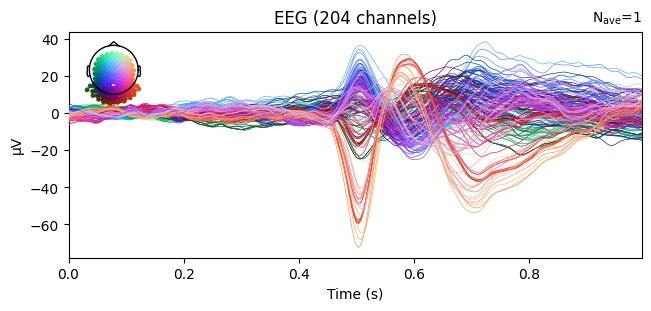

In [13]:
_ = ave.plot()

Measurements - topographies

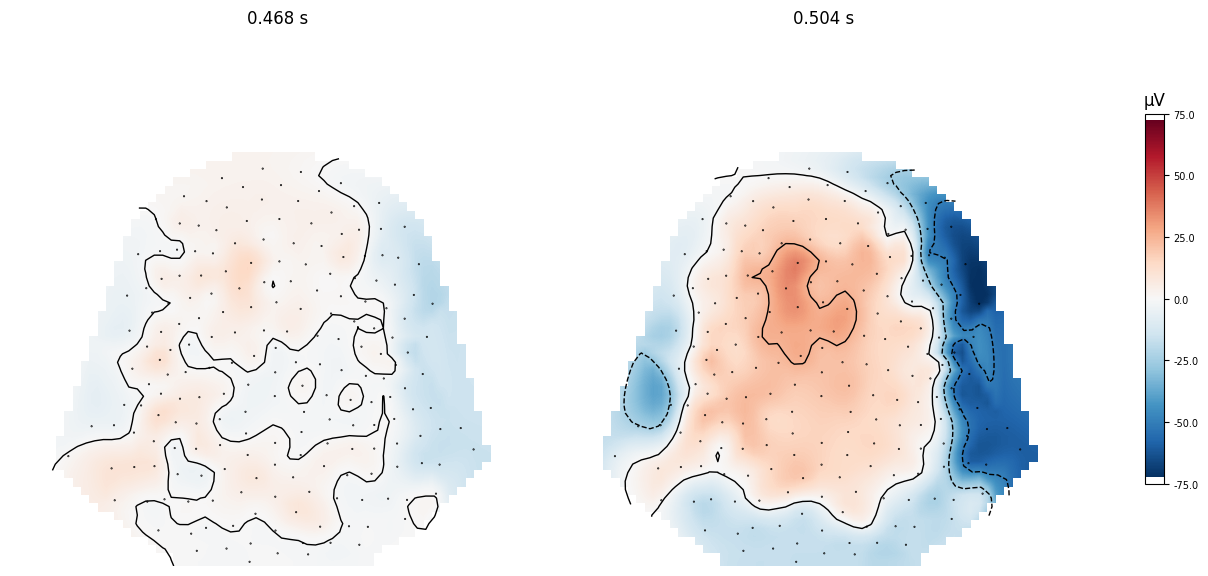

In [14]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.25)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [ ]:
func_params = {"normalize": "max", "absolute": True}
panels = [
    mm.viz.BrainPlot.from_source_space(
        fwd["src"], stc.data, states=stc.times, title=name,
        scalar_name="Source Activity", func_params=func_params,
    )
    for name, stc in [
        #("cset", cset),
        ("wcset", wcset),
        #("mce", mce),
        ("sloreta", sloreta),
        ("dspm", dspm),
    ]
]

# resection (ground truth) as a green point cloud, added to every panel
# with `+`; `toggle` adds a checkbox to hide/show it
resection = mm.viz.SurfacePlot(
    mm.anatomy.mri.nib_to_polydata(resec, trans=ras2tkras).scale(1000),  # m -> mm, like the brain surfaces
    mesh_params={"color": "green", "point_size": 1, "toggle": True},
)

(mm.viz.Layout([panels]) + resection).show(slider_label="Time [s]", jupyter_backend="none")  # native window, not inline

In [ ]:
sr = sloreta
import numpy as np
import matplotlib.pyplot as plt

# Connectome spectrum (|graph Fourier coefficients|) over time.
spectrum = np.abs(eig["vec"].T @ sr.data)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(spectrum, aspect="auto", origin="lower", cmap="viridis",
               extent=[sr.times[0], sr.times[-1], 0, spectrum.shape[0]])
ax.set(title="sloreta", xlabel="Time [s]", ylabel="Harmonic index")
fig.colorbar(im, ax=ax, label="|amplitude|")
fig.tight_layout()

In [ ]:
from mindmap.analysis.functional.common.metric import reconstruct_resection_cluster

# recomputed locally, not reused from the module-level `hrp` -- that name gets
# reassigned to a *time value* (seconds) by the topomap cell above, not an
# index, so relying on it here silently breaks depending on cell run order
hrp_idx = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5, as_idx=True)

# rebuild, for each solver, EVERY cluster active at its own earliest-hit
# threshold (hrp) -- not just the one that officially qualifies (>=
# min_cluster_area and touches the resection). +1 = cluster touches the
# resection, -1 = cluster doesn't, 0 = inactive. Showing all of them (rather
# than just the isolated winner) makes the noise level itself visible: e.g.
# on this subject wcset has exactly one resection-touching cluster at its
# threshold, while sloreta/dspm each have several small extra fragments that
# also happen to graze the resection -- invisible if we only ever plotted the
# single winning cluster
signed_maps = {
    name: reconstruct_resection_cluster(
        recons[name].data[:, hrp_idx], resection_vertex_mask, adjacency, patch_area, hits[(name, "hrp")]["threshold"],
    )["signed_map"]
    for name in recons
}

# don't pass func_params={"absolute": True} here -- that would collapse the
# +1/-1 sign before plotting. clim/cmap go through mesh_params (not
# func_params) and are fixed explicitly so all three panels share the same
# scale and a diverging colormap, regardless of whether a solver happens to
# have zero non-overlapping clusters at its own threshold
panels = [
    mm.viz.BrainPlot.from_source_space(
        fwd["src"], signed_maps[name],
        title=f"{name} (cluster precision = {hits[(name, 'hrp')]['cluster_precision']:.2f})",
        scalar_name="Cluster", mesh_params={"cmap": "bwr", "clim": (-1, 1)},
    )
    for name in recons
]
resection = mm.viz.SurfacePlot(
    mm.anatomy.mri.nib_to_polydata(resec, trans=ras2tkras).scale(1000),  # m -> mm, like the brain surfaces
    mesh_params={"color": "green", "point_size": 1, "toggle": True},
)

(mm.viz.Layout([panels]) + resection).show(jupyter_backend="none")  # native window, not inline

## 🧭 - Honest assessment: is this metric actually good?

Before trusting the numbers above, the obvious question: does `find_earliest_resection_cluster` actually discriminate real localization from noise, or would almost any map "find" this resection quickly just because the resection itself is a decent fraction of cortex? Reproduced below rather than asserted.

In [11]:
# chance baseline for the metric itself -- not the min_cluster_area calibration
# from earlier, which only checked cluster size in isolation. This asks: if
# activity had no spatial structure at all, how much of the cortex would
# find_earliest_resection_cluster need before stumbling into this resection?
rng = np.random.default_rng(1)
n_trials = 200
fractions = []

for _ in range(n_trials):
    random_activity = rng.random(len(resection_vertex_mask))  # pure noise
    hit = find_earliest_resection_cluster(random_activity, resection_vertex_mask, adjacency, patch_area)
    fractions.append(hit["fraction_of_cortex"])

fractions = np.array(fractions)
print(f"pure random activity: mean fraction_of_cortex = {fractions.mean()*100:.1f}%"
      f"  (5th-95th pct: {np.percentile(fractions,5)*100:.1f}%-{np.percentile(fractions,95)*100:.1f}%)")

for name in recons:
    real = hits[(name, "hrp")]["fraction_of_cortex"]
    beat = (fractions <= real).mean()
    print(f"  {name} ({real*100:.1f}%): {beat*100:.1f}% of random trials matched or beat it")

pure random activity: mean fraction_of_cortex = 37.8%  (5th-95th pct: 30.4%-44.5%)
  wcset (1.9%): 0.0% of random trials matched or beat it
  sloreta (3.9%): 0.0% of random trials matched or beat it
  dspm (6.5%): 0.0% of random trials matched or beat it


**The result that matters most**: pure random noise needs, on average, **38% of cortex** before a cluster crosses the size floor and happens to overlap this resection — none of 200 random trials came anywhere close to the real solvers' 1.9–6.5%. That's a real, demonstrated margin, not a small one. This check hadn't been run before it was asked for directly — worth remembering that a metric feeling reasonable in isolation isn't the same as having checked it against chance.

**What's genuinely good about this metric:**
- It's well-posed by construction, not just in practice: a cluster can only grow or merge as the threshold loosens, never shrink, so "has a qualifying cluster touched the resection" is strictly monotonic — there's always a single, unambiguous first-crossing point (proved, then confirmed empirically with zero counterexamples). Most "best cluster across thresholds" schemes, including our own earlier hypergeometric attempt, don't have this property.
- It directly answers the question this whole evaluation effort started from: credit for *any* genuine cluster touching the resection, not just the single global peak.
- `min_cluster_area` is unusually well-grounded for a metric parameter — cross-validated from an independent clinical literature figure and an empirical chance simulation on this exact source space, agreeing within the same order of magnitude.
- `cluster_precision` adds a second, complementary axis almost for free: not just *how early* a cluster was found, but whether it actually grew from inside the resection or merely grazed it from outside — visible directly in the plot above.
- It's legible without statistics training. "How much of the map do you have to trust before something real shows up" doesn't require knowing what a p-value is, unlike AUC-PR or the hypergeometric surprise score.

**Where this stops short of being community-ready:**
- **n = 1.** Everything here, including the chance-baseline check above, is on one patient's one spike average. Whether `min_cluster_area = 600 mm²` or the monotonicity behavior generalizes across resection sizes, etiologies, or SNR regimes is unknown. A metric validated on one subject isn't validated.
- **The 600 mm² floor could systematically penalize real, small epileptogenic zones** — some focal cortical dysplasias are genuinely smaller than that, and would currently look identical to "not found yet."
- **No uncertainty quantification.** If two methods score 1.9% and 3.9% on a different patient, is that a real difference or noise from one spike's average? There's no calibration layer to answer that.
- **Adoption cost.** This needs the geodesic-distance adjacency graph and the native-mesh area computation built over many turns this conversation — not something another lab could drop in the way they could call `sklearn.metrics.precision_recall_curve`.

**Overall**: a genuinely promising idea, more rigorously derived than what the field mostly uses today (still dominated by "distance from the single global maximum," per the literature check earlier in this notebook) — but currently a validated-on-one-patient prototype, not a paper-ready metric. Getting there needs multi-subject validation and the calibration layer, not more cleverness on this one case.

## 📐 - Resection-evaluation metrics reference

- **`find_peak_resection_distance`** — the classic ESI baseline: Euclidean
  distance from the single loudest vertex to the resection's own voxel
  geometry (0 mm if it lands inside). Still the dominant approach in
  clinical ESI literature
  ([EEG source imaging concordance with intracranial EEG and epileptologist
  review in focal epilepsy, Brain Communications, 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC8643498/)),
  kept here as a simple point of comparison — blind to multifocal maps by
  construction, which is why it's read alongside the metric below rather
  than alone.

- **`find_earliest_resection_cluster`** — sweeps the amplitude threshold
  from strict to loose and asks how much of the cortex (by physical area)
  has to be marked active before a connected cluster of at least
  `min_cluster_area` first touches the resection — lower is better.
  Well-posed by construction: a cluster can only grow or merge as the
  threshold loosens, never shrink, so "has a qualifying cluster touched
  the resection" is strictly monotonic in the threshold — there's a single
  unambiguous first-crossing point (found via binary search, cross-checked
  against a local brute-force scan on real data). `cluster_precision`
  separately reports whether that cluster actually grew from inside the
  resection or merely grazed it from outside.

## 📚 - Literature scan: how these metrics compare to prior work

A web search was run (2026-07) to check whether `find_peak_resection_distance` and `find_earliest_resection_cluster` match, or are missing, established methods. Kept here for future reference rather than re-derived each time.

### `find_peak_resection_distance` — direct precedent

This isn't just similar to the literature, it *is* the standard clinical ESI metric, and at least one paper defines it almost identically to our implementation (0 mm if inside, Euclidean distance to the border otherwise):

- **Ye et al., "Contribution of Ictal Source Imaging for Localizing Seizure Onset Zone in Patients With Focal Epilepsy," *Neurology*, 2021, 96(3):e366–e375.** ([PMC7884986](https://pmc.ncbi.nlm.nih.gov/articles/PMC7884986/))
  Defines localization error explicitly as "the distance from the estimated source to the boundary of the resected volume" — same quantity, same units, same 0-if-inside convention used here. Seizure-free patients: mean LE = 0.74 cm (SD 0.79, range 0–2.45 cm).
- **Staljanssens et al., "EEG source connectivity to localize the seizure onset zone in patients with drug resistant epilepsy," *NeuroImage: Clinical*, 2017, 16:689–698.** ([PMC5633847](https://pmc.ncbi.nlm.nih.gov/articles/PMC5633847/))
  The source with maximal power landed *inside* the resected zone in 31% of seizures and within 10 mm of its border in 42% (rising to 72%/94% once functional connectivity is added on top of power) — useful context for what a "good" number looks like on this metric, and an argument for why peak power alone is a weak signal.
- **EEG source imaging concordance with intracranial EEG and epileptologist review in focal epilepsy, *Brain Communications*, 2021.** ([PMC8643498](https://pmc.ncbi.nlm.nih.gov/articles/PMC8643498/)) — already cited elsewhere in this notebook as the general "still the dominant approach" reference.
- Pediatric MEG/HD-EEG/EEG comparison work ([Clinical Neurophysiology](https://www.sciencedirect.com/science/article/pii/S1388245719300288)) reports median distances of 21–33 mm from dipole/distributed-source maxima to SOZ centroid/nearest electrode, and multiple groups report shorter distances in Engel class I (seizure-free) vs. worse outcomes — evidence this distance tracks something clinically real, not just noise.

Take-away: this metric has strong, specific literature backing. Ye et al. 2021 is a tighter methodological match for the actual "0 if inside" distance formula than the Brain Communications paper already cited, worth citing directly if this metric is written up.

### `find_earliest_resection_cluster` — no exact match, but a recognizable family

Nobody phrases it exactly as "binary-search for the first threshold at which a qualifying cluster touches the ground truth," but it sits in a known family of methods:

- **Maris & Oostenveld, "Nonparametric statistical testing of EEG- and MEG-data," *Journal of Neuroscience Methods*, 2007.** ([ResearchGate](https://www.researchgate.net/publication/6316066_Nonparametric_statistical_testing_of_EEG-_and_MEG-data)) and **Smith & Nichols, "Threshold-Free Cluster Enhancement," *NeuroImage*, 2009.** ([overview](https://jaromilfrossard.github.io/permuco4brain/articles/tfce.html)) — the standard M/EEG cluster-based approach: threshold, form connected clusters, test cluster mass/extent. Same core mechanic (threshold → connected components → cluster-level statistic) as `find_earliest_resection_cluster`/`label_clusters`, but built for temporal/statistical significance testing, not "distance in threshold-space to a spatial ground truth."
- **Cluster-extent thresholding in fMRI**, and **"Cluster extent inference revisited: quantification and localisation of brain activity," *JRSSB*, 2023.** ([Oxford Academic](https://academic.oup.com/jrsssb/article/85/4/1128/7218928)) — same general "how big does a surviving cluster need to be to count" question our `min_cluster_area` answers, in a different modality.
- **SISCOM optimal z-threshold selection** ([PMC5904095](https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5904095/)) and **ASL adaptive thresholding for epileptogenic-zone detection** ([AJNR](https://www.ajnr.org/content/33/9/1818)) — both explicitly grapple with "which threshold" the way we do, but resolve it by picking one "optimal" operating point (e.g. z > 1.64, or a 95th-percentile cut) rather than sweeping and reporting the earliest crossing.
- The **6–10 cm² minimum-active-cortex figure** already used for `min_cluster_area = 600 mm²` is well-supported independently ([Grova et al., NeuroImage, 2006](https://www.sciencedirect.com/science/article/abs/pii/S1053811905006373)): intracranial-to-scalp concordance work puts the true floor near 6 cm², with <6 cm² essentially never producing a scalp-visible spike, and 10–20 cm² more typical in practice.
- **FROC/JAFROC** and **Kulldorff's spatial scan statistic** (previously catalogued in this notebook's roadmap, before it was trimmed down) remain the closest formal treatments of "sweep candidate regions, take credit for any hit" — worth remembering these exist in the library history even though the roadmap listing them was removed from this notebook.

Take-away: `find_peak_resection_distance` replicates a specific, named clinical metric almost exactly. `find_earliest_resection_cluster` has no single direct analog, but is a defensible hybrid of cluster-extent thresholding (Maris & Oostenveld/TFCE lineage) and the "optimal threshold search" idea used in SISCOM/ASL epileptogenic-zone work — genuinely closer to novel than the distance metric, consistent with this notebook's own "honest assessment" section above.